# The Geometric Factors

The marginalized likelihood ratio of the paper is a sum of data factors $T^{(n)}_{ab}(\tau)$ times geometric factors $W^{(n)}_{ab}(\tau, u_1, u_2)$, the generalized overlap reduction functions (GORFs) of Eq. (23). The geometric factors do not depend on the data. They are averages of the detector responses over the sky position, the polarization, the inclination and the distance in Eq. (29), so we compute them once and save them.

This notebook builds the tables with `exmarg.w_table_par`, saves them and draws Figs. 3, 4, 5, 14 and 15 of the paper. Each table here takes a few seconds, and the production tables at orders up to 120 come from the same function (last section).

In [1]:
import sys
sys.path.insert(0, '../src')        # the exmarg package of this repository

import time
import numpy as np
import exmarg
import figures_method as figures

## The Distance Prior

The tables average the distance weight $M_n(A) = \int dy\, p(y)\, y^{2n} e^{-y^2 A}$ over a prior on $y = D_0/D$. We use the prior of the simulated year of the paper, the distance distribution of mergers that follow the Madau-Dickinson rate history out to $z = 8$.

In [2]:
exmarg.use_distance_prior('madau-dickinson')
ymin = exmarg.madau_dickinson_ymin()
print('smallest y = D0/D of the prior:', round(ymin, 4))

smallest y = D0/D of the prior: 0.0982


## Build the Tables

We build two filter powers, $u = 1$ and $u = 20$ in both detectors, at every order up to $n = 3$. `nside` is the HEALPix resolution of the sky average and `n_tau` the number of delay bins.

In [3]:
u_values = np.array([1.0, 20.0])

start = time.time()
tau, W = exmarg.w_table_par(u_values, u_values, ymin, 3, n_tau=8193, nside=128, workers=8)
print('built in %.1f s' % (time.time() - start))

# W[0] holds the tables of u = 1 and W[1] those of u = 20.
# W[0][(n, a, b)] is W^(n)_ab as a function of the delay tau (in seconds).
print('tables per filter power:', len(W[0]))

built in 1.7 s
tables per filter power: 30


## Save the Tables

Each filter power goes into one file with the delay grid and one array per $(n, a, b)$.

In [4]:
import os
os.makedirs('tables', exist_ok=True)
for i, u in enumerate(u_values):
    rows = {}
    for (n, a, b), row in W[i].items():
        rows['W_%d%d%d' % (n, a, b)] = row
    np.savez('tables/W_u%g.npz' % u, tau=tau, **rows)
    print('saved tables/W_u%g.npz' % u)

saved tables/W_u1.npz
saved tables/W_u20.npz


## The GORFs at Two Filter Powers (Fig. 3)

We read the tables back, put them on a coarse grid of 201 delays and draw each $W^{(n)}_{ab}(\tau)$ scaled to its largest value.

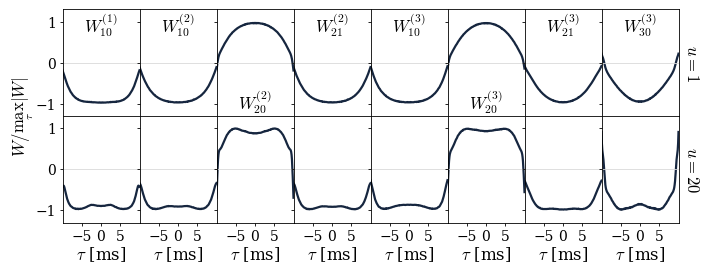

In [5]:
keys = [(1, 1, 0), (2, 1, 0), (2, 2, 0), (2, 2, 1), (3, 1, 0), (3, 2, 0), (3, 2, 1), (3, 3, 0)]

rows = []
for u in u_values:
    saved = np.load('tables/W_u%g.npz' % u)
    table = {}
    for (n, a, b) in keys:
        table[(n, a, b)] = saved['W_%d%d%d' % (n, a, b)]
    tau_show, rows_u = exmarg.geometry.display_rows(saved['tau'], table, keys, 201)
    rows.append(rows_u)

figures.fig_W_family(tau_show, u_values, np.array(keys), np.array(rows))

## The First-Order GORF and Its Fourier Transform (Fig. 4)

We show the first-order table $W^{(1)}_{10}(\tau)$ for a ladder of filter powers with equal filter powers, with a second detector ten times weaker and without a second detector, where a tiny $u_2$ stands for $u_2 = 0$. Its Fourier transform over the delay is the generalized overlap reduction function in frequency.

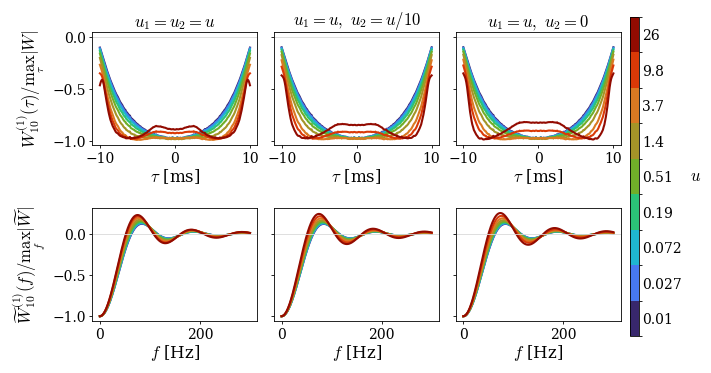

In [6]:
ladder = np.geomspace(0.01, 26.2, 9)
cases = [ladder, ladder / 10.0, np.full(ladder.size, 1e-8)]

frequencies = np.linspace(0.0, 300.0, 601)
all_rows = []
all_transforms = []
for u2 in cases:
    tau1, W1 = exmarg.w_table_par(ladder, u2, ymin, 1, n_tau=8193, nside=128, workers=8)
    for table in W1:
        tau_show, row = exmarg.geometry.display_rows(tau1, table, [(1, 1, 0)], 201)
        row = row[0]
        dtau = tau_show[1] - tau_show[0]
        transform = np.array([np.sum(row * np.cos(2 * np.pi * f * tau_show)) * dtau for f in frequencies])
        all_rows.append(row)
        all_transforms.append(transform)

figures.fig_W_u0(tau_show, frequencies, ladder, np.array(all_rows), np.array(all_transforms))

## Higher-Order GORFs in the Weak-Signal Limit (Fig. 5)

In the weak-signal limit the Fourier transforms of the second-order tables give the functions $\Gamma^{(4)}$ of Eq. (31). `frequency_slices` averages the responses over the sky and the orientation and transforms the slices of the paper.

first zero of the standard ORF: 64 Hz


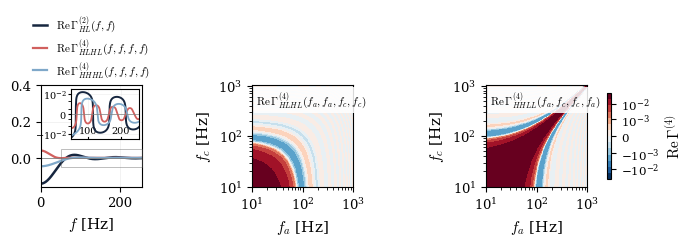

In [7]:
f1, gamma2_HL, gamma4_HLHL, gamma4_HHHL, f2, pair_surface, intensity_surface = exmarg.geometry.frequency_slices()

first_zero = f1[np.argmax(np.diff(np.sign(gamma2_HL.real)) != 0)]
print('first zero of the standard ORF: %.0f Hz' % first_zero)

figures.fig_orf_side(f1, gamma2_HL, gamma4_HLHL, gamma4_HHHL, f2, pair_surface, intensity_surface)

## Resolution of the Sky Average (Fig. 15)

The sky average is a sum over HEALPix pixels, and at low resolution the table oscillates on the pixel scale.

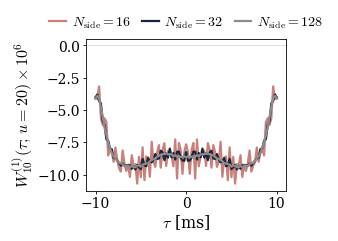

In [8]:
nsides = [16, 32, 128]
rows = []
for nside in nsides:
    tau_n, W_n = exmarg.w_table_par(20.0, 20.0, ymin, 1, n_tau=8193, nside=nside, workers=8)
    tau_show, row = exmarg.geometry.display_rows(tau_n, W_n, [(1, 1, 0)], 101)
    rows.append(row[0])

figures.fig_W_nside(tau_show, np.array(nsides), np.array(rows))

## The Truncation Deficit (Fig. 14)

Under noise the series truncated at $n_{\max}$ has the mean $1 - \epsilon_{n_{\max}}$ of Eq. (B4), where $\epsilon_{n_{\max}}$ of Eq. (B5) is the probability that a Poisson number with mean $A y^2$ exceeds $n_{\max}$, averaged over the orientation and the distance prior. The red segment marks the filter powers of the templates between 20 and $200\,M_\odot$ in detector-frame total mass.

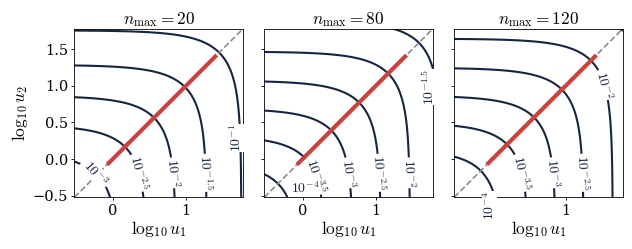

In [9]:
u_grid = np.geomspace(0.3, 60.0, 56)
deficit = exmarg.geometry.truncation_deficit(u_grid, [20, 80, 120])
template_powers = np.array([0.84, 26.2])

figures.fig_eps_u1u2(u_grid, template_powers, deficit)

## The Production Tables

The analysis uses the same function at orders up to $n_{\max} = 120$ with `nside = 32` on a ladder of filter powers, and every order is then summed into one table per filter power (Appendix C) so that analyzing a segment costs the same at any $n_{\max}$. These builds take hours on many cores, so they run as scripts and the finished tables are downloaded (see the README).

    python scripts/build_tables/build_w.py <w_dir>
    python scripts/build_tables/build_k.py prepare <w_dir> <k_dir> <node>
    python scripts/build_tables/build_k.py slab <w_dir> <k_dir> <node> <k> <K>
    python scripts/build_tables/build_k.py finalize <w_dir> <k_dir> <node>
    python scripts/build_tables/build_bd.py <k_dir> tables/redshift

The cell below makes the same call at production depth for one filter power and is not run here.

In [10]:
# tau, W = exmarg.w_table_par(20.0, 20.0, ymin, 120, nside=32, workers=64)